In [1]:
import matplotlib.pyplot as plt

import sys
sys.path.append('../../')

# Import methods
import QGP.Defocusing.Methods as QGP
import NLS_Cubic.Methods as NLS
from QGP.Soliton_Gen import *
from Utilities import *

import config

i = 1j

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


# Black soliton errors

In [2]:
L = 20
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

def black_theo_NLS(x, t):
    black_soliton = lambda x, t: np.exp(-i * t) * w_soliton(x)
    return black_soliton(x - c * t, t)

Creating soliton...
Soliton created


In [4]:
dts = np.array([2**(-j) for j in range(1, 11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))

error_1_NLS = np.zeros(len(dts))
error_2_NLS = np.zeros(len(dts))

pars_GP = {"k": 0}
pars_NLS = {"k": -1}

ws_1_GP = []
ws_2_GP = []

ws_1_NLS = []
ws_2_NLS = []

# N_1
for dt in dts:
    w_ = QGP.CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]
    
    w_ = NLS.CNFD(L, N_1, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_1_NLS += [w_]

# N_2
for dt in dts:
    w_ = QGP.CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]
    
    w_ = NLS.CNFD(L, N_2, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_2_NLS += [w_]

In [5]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_GP[j]
    w_GP.solve()
    
    w_NLS = ws_1_NLS[j]
    w_NLS.solve()

Iteration  0  of  5 . Error:  9.723044850997205e-09
Iteration  1  of  5 . Error:  8.474228012438433e-09
Iteration  2  of  5 . Error:  6.773449149012933e-09
Iteration  3  of  5 . Error:  4.732764153572334e-09
Iteration  4  of  5 . Error:  6.388767441427168e-09
Iteration  5  of  5 . Error:  7.70964604440318e-09
Iteration  0  of  11 . Error:  4.449715320946692e-09
Iteration  1  of  11 . Error:  6.217084974772962e-09
Iteration  2  of  11 . Error:  8.726749697117971e-09
Iteration  3  of  11 . Error:  1.7771259323647436e-09
Iteration  4  of  11 . Error:  2.281272945302098e-09
Iteration  5  of  11 . Error:  2.7472277487736034e-09
Iteration  6  of  11 . Error:  3.1315031464822655e-09
Iteration  7  of  11 . Error:  3.4218234146733957e-09
Iteration  8  of  11 . Error:  3.628143833312364e-09
Iteration  9  of  11 . Error:  3.769014825694638e-09
Iteration  10  of  11 . Error:  3.862743446902564e-09
Iteration  11  of  11 . Error:  3.9240540506875765e-09
Iteration  0  of  23 . Error:  4.6898321415986

In [6]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()
    
    w_NLS = ws_2_NLS[j]
    w_NLS.solve()

Iteration  0  of  5 . Error:  9.349233749219698e-09
Iteration  1  of  5 . Error:  8.471491802313086e-09
Iteration  2  of  5 . Error:  6.9449227184178675e-09
Iteration  3  of  5 . Error:  4.901385856592194e-09
Iteration  4  of  5 . Error:  6.6191960859939265e-09
Iteration  5  of  5 . Error:  7.94141372786543e-09
Iteration  0  of  11 . Error:  1.8677115330076684e-09
Iteration  1  of  11 . Error:  2.717828473403338e-09
Iteration  2  of  11 . Error:  3.984658322424228e-09
Iteration  3  of  11 . Error:  5.556714440527584e-09
Iteration  4  of  11 . Error:  7.1760399503109715e-09
Iteration  5  of  11 . Error:  8.59445056543648e-09
Iteration  6  of  11 . Error:  9.693699713866283e-09
Iteration  7  of  11 . Error:  1.6741582437240506e-09
Iteration  8  of  11 . Error:  1.7713465887345688e-09
Iteration  9  of  11 . Error:  1.8362966624412726e-09
Iteration  10  of  11 . Error:  1.8789372390852026e-09
Iteration  11  of  11 . Error:  1.9064281635386754e-09
Iteration  0  of  23 . Error:  1.9784037064

In [7]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [8]:
for j in range(len(dts)):
    e_1 = ws_1_NLS[j].get_error(tf)
    e_2 = ws_2_NLS[j].get_error(tf)
    
    error_1_NLS[j] = e_1
    error_2_NLS[j] = e_2

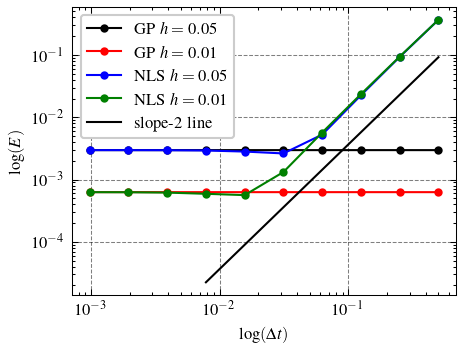

In [12]:
dts_to_plot = dts[:-3]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.05$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.01$")

plt.plot(dts, error_1_NLS, ".-", label=r"NLS $h=0.05$")
plt.plot(dts, error_2_NLS, ".-", label=r"NLS $h=0.01$")
plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/comp_error_black.pgf", dpi=300, bbox_inches = "tight")
plt.show()

# Dark soliton errors

## Gross pitaevskii soliton

In [13]:
L = 20
c = np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

def black_theo_NLS(x, t):
    black_soliton = lambda x, t: np.exp(-i * t) * w_soliton(x)
    return black_soliton(x + c * t, t)

Creating soliton...
Soliton created


In [16]:
dts = np.array([2**(-j) for j in range(1, 11)])

# Time
tf = 3

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))

error_1_NLS = np.zeros(len(dts))
error_2_NLS = np.zeros(len(dts))

pars_GP = {"k": 0}
pars_NLS = {"k": -1}

ws_1_GP = []
ws_2_GP = []

ws_1_NLS = []
ws_2_NLS = []

# N_1
for dt in dts:
    w_ = QGP.CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]
    
    w_ = NLS.CNFD(L, N_1, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_1_NLS += [w_]

# N_2
for dt in dts:
    w_ = QGP.CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]
    
    w_ = NLS.CNFD(L, N_2, dt, tf, pars_NLS, "neumann")
    w_.set_w_theo(black_theo_NLS)
    ws_2_NLS += [w_]

In [17]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_GP[j]
    w_GP.solve()
    
    w_NLS = ws_1_NLS[j]
    w_NLS.solve()

Iteration  0  of  5 . Error:  9.649008635627867e-09
Iteration  1  of  5 . Error:  9.642443840098744e-09
Iteration  2  of  5 . Error:  9.59877796518987e-09
Iteration  3  of  5 . Error:  9.572384452258697e-09
Iteration  4  of  5 . Error:  9.651024207213138e-09
Iteration  5  of  5 . Error:  9.878722744189753e-09
Iteration  0  of  11 . Error:  6.354691904192609e-09
Iteration  1  of  11 . Error:  6.363174573127951e-09
Iteration  2  of  11 . Error:  6.370363682636088e-09
Iteration  3  of  11 . Error:  6.378476445551385e-09
Iteration  4  of  11 . Error:  6.392385278855433e-09
Iteration  5  of  11 . Error:  6.4118009317671e-09
Iteration  6  of  11 . Error:  6.432287395252115e-09
Iteration  7  of  11 . Error:  6.450972190882974e-09
Iteration  8  of  11 . Error:  6.467271541086113e-09
Iteration  9  of  11 . Error:  6.481181481282181e-09
Iteration  10  of  11 . Error:  6.492486549377456e-09
Iteration  11  of  11 . Error:  6.500896170334255e-09
Iteration  0  of  23 . Error:  1.3473074816249483e-09

In [18]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()
    
    w_NLS = ws_2_NLS[j]
    w_NLS.solve()

Iteration  0  of  5 . Error:  9.147173184638088e-09
Iteration  1  of  5 . Error:  9.087387920048456e-09
Iteration  2  of  5 . Error:  8.963461742797305e-09
Iteration  3  of  5 . Error:  8.848319808622738e-09
Iteration  4  of  5 . Error:  8.856327301973034e-09
Iteration  5  of  5 . Error:  9.049600950729722e-09
Iteration  0  of  11 . Error:  3.627026348452147e-09
Iteration  1  of  11 . Error:  3.6256071444762543e-09
Iteration  2  of  11 . Error:  3.6223695192347886e-09
Iteration  3  of  11 . Error:  3.6205351273216674e-09
Iteration  4  of  11 . Error:  3.625398306343961e-09
Iteration  5  of  11 . Error:  3.6380493611494914e-09
Iteration  6  of  11 . Error:  3.6549120466825032e-09
Iteration  7  of  11 . Error:  3.6718996171307347e-09
Iteration  8  of  11 . Error:  3.6868857120430555e-09
Iteration  9  of  11 . Error:  3.6990622501882987e-09
Iteration  10  of  11 . Error:  3.7086325463868695e-09
Iteration  11  of  11 . Error:  3.7155905336892806e-09
Iteration  0  of  23 . Error:  3.0133156

In [19]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [20]:
for j in range(len(dts)):
    e_1 = ws_1_NLS[j].get_error(tf)
    e_2 = ws_2_NLS[j].get_error(tf)
    
    error_1_NLS[j] = e_1
    error_2_NLS[j] = e_2

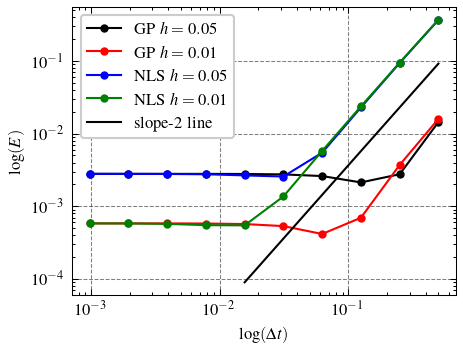

In [34]:
dts_to_plot = dts[:-4]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.05$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.01$")

plt.plot(dts, error_1_NLS, ".-", label=r"NLS $h=0.05$")
plt.plot(dts, error_2_NLS, ".-", label=r"NLS $h=0.01$")

plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/comp_error_dark.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## QGP dark $D_1$ soliton error

In [23]:
# Create solitons
L = 40
N = 10_001
k = 1/4

pars = {"k":k}

c = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


/Users/sebatapia/Desktop/Phd/Nonlinear_Schrodinger/Tests/Comparisons/../../QGP/Soliton_Gen.py:219: RuntimeWarning: Results obtained with less than 2 decimal digits of accuracy
  warnings.warn("Results obtained with less than %g "


In [26]:
def dark_theo_QGP(x, t):
    return w_dark(x - c * t)

In [28]:
dts = np.array([2**(-j) for j in range(1, 11)])

# Time
tf = 5

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_QGP = np.zeros(len(dts))
error_2_QGP = np.zeros(len(dts))

pars_QGP = {"k": k}

ws_1_QGP = []
ws_2_QGP = []

# N_1
for dt in dts:
    w_ = QGP.CNFD(L, N_1, dt, tf, pars_QGP, "neumann")
    w_.set_w_theo(dark_theo_QGP)
    ws_1_QGP += [w_]

# N_2
for dt in dts:
    w_ = QGP.CNFD(L, N_2, dt, tf, pars_QGP, "neumann")
    w_.set_w_theo(dark_theo_QGP)
    ws_2_QGP += [w_]

In [29]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_QGP[j]
    w_GP.solve()

Iteration  0  of  9 . Error:  8.993037145386636e-09
Iteration  1  of  9 . Error:  8.939035803559639e-09
Iteration  2  of  9 . Error:  8.88010325420946e-09
Iteration  3  of  9 . Error:  8.858544476577928e-09
Iteration  4  of  9 . Error:  8.917253815302699e-09
Iteration  5  of  9 . Error:  9.076652702636492e-09
Iteration  6  of  9 . Error:  9.340614546515329e-09
Iteration  7  of  9 . Error:  9.705240912711505e-09
Iteration  8  of  9 . Error:  8.75654300891266e-09
Iteration  9  of  9 . Error:  9.250650728170824e-09
Iteration  0  of  19 . Error:  8.569263733902059e-09
Iteration  1  of  19 . Error:  8.570605970264518e-09
Iteration  2  of  19 . Error:  8.573114779141177e-09
Iteration  3  of  19 . Error:  8.578221744435445e-09
Iteration  4  of  19 . Error:  8.587348349222548e-09
Iteration  5  of  19 . Error:  8.599220400880117e-09
Iteration  6  of  19 . Error:  8.611431025448291e-09
Iteration  7  of  19 . Error:  8.623295953774797e-09
Iteration  8  of  19 . Error:  8.635375087604447e-09
Itera

In [30]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_QGP[j]
    w_GP.solve()

Iteration  0  of  9 . Error:  9.52238448834458e-09
Iteration  1  of  9 . Error:  9.417871251952181e-09
Iteration  2  of  9 . Error:  9.283986878305458e-09
Iteration  3  of  9 . Error:  9.18571136305425e-09
Iteration  4  of  9 . Error:  9.191570760275858e-09
Iteration  5  of  9 . Error:  9.335465706233182e-09
Iteration  6  of  9 . Error:  9.621548198212373e-09
Iteration  7  of  9 . Error:  8.643397277082181e-09
Iteration  8  of  9 . Error:  9.101481016227551e-09
Iteration  9  of  9 . Error:  9.661439581374784e-09
Iteration  0  of  19 . Error:  5.5894465247920204e-09
Iteration  1  of  19 . Error:  5.583038530715828e-09
Iteration  2  of  19 . Error:  5.5774343305800884e-09
Iteration  3  of  19 . Error:  5.576252117494897e-09
Iteration  4  of  19 . Error:  5.582413686485181e-09
Iteration  5  of  19 . Error:  5.594503051172925e-09
Iteration  6  of  19 . Error:  5.608313919720274e-09
Iteration  7  of  19 . Error:  5.6205640347501995e-09
Iteration  8  of  19 . Error:  5.630747048722537e-09
It

In [31]:
for j in range(len(dts)):
    e_1 = ws_1_QGP[j].get_error(tf)
    e_2 = ws_2_QGP[j].get_error(tf)
    
    error_1_QGP[j] = e_1
    error_2_QGP[j] = e_2

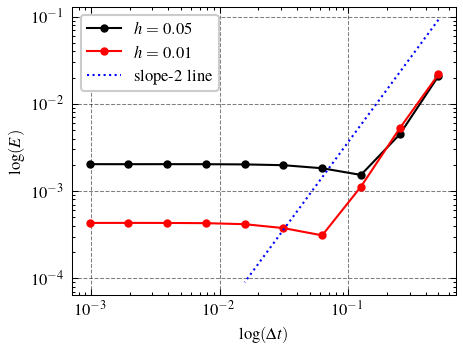

In [32]:
dts_to_plot = dts[:-4]
plt.plot(dts, error_1_QGP, ".-", label=r"$h=0.05$")
plt.plot(dts, error_2_QGP, ".-", label=r"$h=0.01$")

plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/error_dark_QGP.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## QGP dark $D_2$ soliton error

### Stable soliton

In [38]:
# Create solitons
L = 80
N = 10_001
k = -20

pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_in = c_star + eps

c = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [39]:
def dark_theo_QGP(x, t):
    return w_dark(x - c * t)

In [40]:
dts = np.array([2**(-j) for j in range(1, 9)])

# Time
tf = 10

# Space
h_1 = 0.05
h_2 = 0.01

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_QGP = np.zeros(len(dts))
error_2_QGP = np.zeros(len(dts))

pars_QGP = {"k": k}

ws_1_QGP = []
ws_2_QGP = []

# N_1
for dt in dts:
    w_ = QGP.CNFD(L, N_1, dt, tf, pars_QGP, "neumann")
    w_.set_w_theo(dark_theo_QGP)
    ws_1_QGP += [w_]

# N_2
for dt in dts:
    w_ = QGP.CNFD(L, N_2, dt, tf, pars_QGP, "neumann")
    w_.set_w_theo(dark_theo_QGP)
    ws_2_QGP += [w_]

In [41]:
# N_1
for j in range(len(dts)):
    w_GP = ws_1_QGP[j]
    w_GP.solve()

Iteration  0  of  19 . Error:  9.838074846689612e-09
Iteration  1  of  19 . Error:  9.78666117508353e-09
Iteration  2  of  19 . Error:  9.574596219267412e-09
Iteration  3  of  19 . Error:  9.266062902291244e-09
Iteration  4  of  19 . Error:  9.661090437651014e-09
Iteration  5  of  19 . Error:  9.655586019370311e-09
Iteration  6  of  19 . Error:  9.438033707031764e-09
Iteration  7  of  19 . Error:  9.621519979655704e-09
Iteration  8  of  19 . Error:  9.253105862978608e-09
Iteration  9  of  19 . Error:  9.294818450607778e-09
Iteration  10  of  19 . Error:  9.27258776559153e-09
Iteration  11  of  19 . Error:  9.662476417284075e-09
Iteration  12  of  19 . Error:  9.860715649612923e-09
Iteration  13  of  19 . Error:  9.816980436589548e-09
Iteration  14  of  19 . Error:  9.797309995378965e-09
Iteration  15  of  19 . Error:  9.524615605546746e-09
Iteration  16  of  19 . Error:  9.838531207675947e-09
Iteration  17  of  19 . Error:  9.637463364882233e-09
Iteration  18  of  19 . Error:  9.561146

In [42]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_QGP[j]
    w_GP.solve()

Iteration  0  of  19 . Error:  9.701520453279061e-09
Iteration  1  of  19 . Error:  9.64996832803154e-09
Iteration  2  of  19 . Error:  9.990709969691788e-09
Iteration  3  of  19 . Error:  9.656223464060348e-09
Iteration  4  of  19 . Error:  9.789993436628002e-09
Iteration  5  of  19 . Error:  9.645853465468353e-09
Iteration  6  of  19 . Error:  9.90244068428321e-09
Iteration  7  of  19 . Error:  9.423671937892428e-09
Iteration  8  of  19 . Error:  9.681532447805224e-09
Iteration  9  of  19 . Error:  9.533681042467901e-09
Iteration  10  of  19 . Error:  9.743873823656848e-09
Iteration  11  of  19 . Error:  9.882180735352197e-09
Iteration  12  of  19 . Error:  9.929486914718826e-09
Iteration  13  of  19 . Error:  9.657807164866165e-09
Iteration  14  of  19 . Error:  9.607064663526722e-09
Iteration  15  of  19 . Error:  9.465687902651334e-09
Iteration  16  of  19 . Error:  9.874131214258398e-09
Iteration  17  of  19 . Error:  9.703022406128005e-09
Iteration  18  of  19 . Error:  9.646331

In [43]:
for j in range(len(dts)):
    e_1 = ws_1_QGP[j].get_error(tf)
    e_2 = ws_2_QGP[j].get_error(tf)
    
    error_1_QGP[j] = e_1
    error_2_QGP[j] = e_2

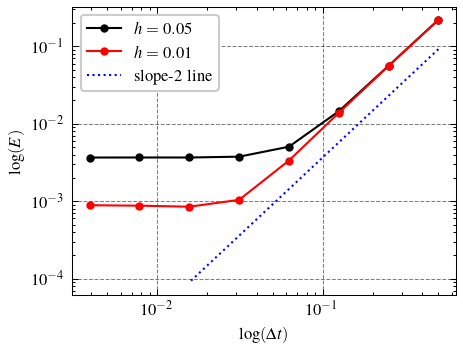

In [47]:
dts_to_plot = dts[:-2]
plt.plot(dts, error_1_QGP, ".-", label=r"$h=0.05$")
plt.plot(dts, error_2_QGP, ".-", label=r"$h=0.01$")

plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

plt.savefig("Img/error_dark_D2_st_QGP.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## GP Black soliton lower h

In [48]:
L = 20
c = 0 #np.sqrt(2)/2
w_soliton, x_soliton = soliton(c, 0, soliton_type="dark", L=L, N=10_000, as_func=True)

def black_theo_GP(x, t):
    return w_soliton(x - c * t)

Creating soliton...
Soliton created


In [61]:
dts = np.array([2**(-j) for j in range(1, 5)])

# Time
tf = 3

# Space
h_1 = 0.005
h_2 = 0.001

N_1 = int(2*L/h_1)
N_2 = int(2*L/h_2)

error_1_GP = np.zeros(len(dts))
error_2_GP = np.zeros(len(dts))


pars_GP = {"k": 0}

ws_1_GP = []
ws_2_GP = []


# N_1
for j in range(len(dts)):
    dt = dts[j]
    w_ = QGP.Complex_CNFD(L, N_1, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_1_GP += [w_]

# N_2
for dt in dts:
    w_ = QGP.Complex_CNFD(L, N_2, dt, tf, pars_GP, "neumann")
    w_.set_w_theo(black_theo_GP)
    ws_2_GP += [w_]

In [62]:
# N_1
for j in range(len(dts)):
    print("Solving ", j, " of ", len(dts)-1)
    w_GP = ws_1_GP[j]
    w_GP.solve()

Solving  0  of  3


KeyboardInterrupt: 

In [ ]:
# N_2
for j in range(len(dts)):
    w_GP = ws_2_GP[j]
    w_GP.solve()

In [ ]:
for j in range(len(dts)):
    e_1 = ws_1_GP[j].get_error(tf)
    e_2 = ws_2_GP[j].get_error(tf)
    
    error_1_GP[j] = e_1
    error_2_GP[j] = e_2

In [ ]:
dts_to_plot = dts[:-4]
plt.plot(dts, error_1_GP, ".-", label=r"GP $h=0.005$")
plt.plot(dts, error_2_GP, ".-", label=r"GP $h=0.001$")

#plt.plot(dts_to_plot, dts_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(\Delta t)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

#plt.savefig("Img/comp_error_dark.png", dpi=300, bbox_inches = "tight")
plt.show()

## Dark $D_1$ soliton convergence in space

In [2]:
# Create solitons
L = 40
N = 20_001
k = 1/4

pars = {"k":k}

c = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [3]:
def dark_theo_QGP(x, t):
    return w_dark(x - c * t)

In [4]:
Ns = np.array([2**(j) for j in range(5, 15)])

# Time
tf = 5

# Space
dt_1 = 0.05
dt_2 = 0.005

error_1_QGP = np.zeros(len(Ns))
error_2_QGP = np.zeros(len(Ns))

pars_QGP = {"k": k}

ws_1_QGP = []
ws_2_QGP = []

# N_1
for N in Ns:
    w_ = QGP.CNFD(L, N, dt_1, tf, pars_QGP, "neumann", order=2)
    w_.set_w_theo(dark_theo_QGP)
    ws_1_QGP += [w_]

# N_2
for N in Ns:
    w_ = QGP.CNFD(L, N, dt_2, tf, pars_QGP, "neumann", order=2)
    w_.set_w_theo(dark_theo_QGP)
    ws_2_QGP += [w_]

In [5]:
# N_1
for j in range(len(Ns)):
    w_GP = ws_1_QGP[j]
    w_GP.solve()

Iteration  0  of  99 . Newton Error:  5.322361458122158e-13 . Total iteration:  3
Iteration  1  of  99 . Newton Error:  5.3233514156591e-13 . Total iteration:  3
Iteration  2  of  99 . Newton Error:  5.323790585446308e-13 . Total iteration:  3
Iteration  3  of  99 . Newton Error:  5.32000189859693e-13 . Total iteration:  3
Iteration  4  of  99 . Newton Error:  5.316543116519385e-13 . Total iteration:  3
Iteration  5  of  99 . Newton Error:  5.311608593034e-13 . Total iteration:  3
Iteration  6  of  99 . Newton Error:  5.30584512969774e-13 . Total iteration:  3
Iteration  7  of  99 . Newton Error:  5.300165957185771e-13 . Total iteration:  3
Iteration  8  of  99 . Newton Error:  5.293461429802886e-13 . Total iteration:  3
Iteration  9  of  99 . Newton Error:  5.288305186060309e-13 . Total iteration:  3
Iteration  10  of  99 . Newton Error:  5.282150427672129e-13 . Total iteration:  3
Iteration  11  of  99 . Newton Error:  5.278872061049244e-13 . Total iteration:  3
Iteration  12  of  99

In [6]:
# N_2
for j in range(len(Ns)):
    w_GP = ws_2_QGP[j]
    w_GP.solve()

Iteration  0  of  999 . Newton Error:  4.639609241093438e-16 . Total iteration:  3
Iteration  1  of  999 . Newton Error:  4.0281251041050643e-16 . Total iteration:  3
Iteration  2  of  999 . Newton Error:  4.3911247670016983e-16 . Total iteration:  3
Iteration  3  of  999 . Newton Error:  3.945566155637455e-16 . Total iteration:  3
Iteration  4  of  999 . Newton Error:  4.0513322805512724e-16 . Total iteration:  3
Iteration  5  of  999 . Newton Error:  3.901043097527373e-16 . Total iteration:  3
Iteration  6  of  999 . Newton Error:  4.383158571949797e-16 . Total iteration:  3
Iteration  7  of  999 . Newton Error:  3.860709309012677e-16 . Total iteration:  3
Iteration  8  of  999 . Newton Error:  4.414969964302553e-16 . Total iteration:  3
Iteration  9  of  999 . Newton Error:  3.706115245449482e-16 . Total iteration:  3
Iteration  10  of  999 . Newton Error:  4.576587843153969e-16 . Total iteration:  3
Iteration  11  of  999 . Newton Error:  3.8088307559711512e-16 . Total iteration:  

In [9]:
for j in range(len(Ns)):
    e_1 = ws_1_QGP[j].get_error(tf)
    e_2 = ws_2_QGP[j].get_error(tf)
    
    error_1_QGP[j] = e_1
    error_2_QGP[j] = e_2

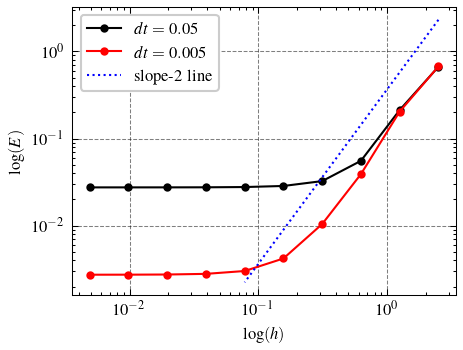

In [10]:
hs = 2*L/Ns
hs_to_plot = hs[:-4]

plt.plot(hs, error_1_QGP, ".-", label=r"$dt=0.05$")
plt.plot(hs, error_2_QGP, ".-", label=r"$dt=0.005$")

plt.plot(hs_to_plot, hs_to_plot**2*np.exp(-1), label="slope-{} line".format(2))

plt.yscale("log")
plt.xscale("log")

plt.xlabel(r"$\log(h)$")
plt.ylabel(r"$\log(E)$")

plt.legend()

#plt.savefig("Img/error_space_dark_D1_QGP_2.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [40]:
EOC_1 = []
EOC_2 = []

for j in range(len(Ns)-1):
    EOC_1 += [np.log2(error_1_QGP[j]/error_1_QGP[j+1])]
    EOC_2 += [np.log2(error_2_QGP[j]/error_2_QGP[j+1])]

In [41]:
import pandas as pd

df_EOC = pd.DataFrame({"EOC dt=0.05": EOC_1, "EOC dt=0.005": EOC_2})
df_EOC.index = list(Ns)[:-1]
print(df_EOC)

      EOC dt=0.05  EOC dt=0.005
32       1.893643      1.946697
64       2.252403      2.633888
128      0.665663      1.638077
256     -0.019642      1.065128
512     -0.073675      0.868415
1024    -0.048974      0.222096
2048    -0.027247     -0.149562
4096    -0.014288     -0.126746
8192    -0.007307     -0.070733


In [35]:
import pandas as pd

df_EOC = pd.DataFrame({"EOC dt=0.05": EOC_1, "EOC dt=0.005": EOC_2})
df_EOC.index = list(Ns)[:-1]
print(df_EOC)

      EOC dt=0.05  EOC dt=0.005
32       1.893643      1.946697
64       2.252403      2.633888
128      0.665663      1.638077
256     -0.019642      1.065128
512     -0.073675      0.868415
1024    -0.048974      0.222096
2048    -0.027247     -0.149562
4096    -0.014288     -0.126746
8192    -0.007307     -0.070733


In [26]:
import pandas as pd

df_EOC = pd.DataFrame({"EOC dt=0.05": EOC_1, "EOC dt=0.005": EOC_2})
df_EOC.index = list(Ns)[:-1]
print(df_EOC)

      EOC dt=0.05  EOC dt=0.005
32       1.893643      1.946697
64       2.252403      2.633888
128      0.665663      1.638077
256     -0.019642      1.065128
512     -0.073675      0.868415
1024    -0.048974      0.222096
2048    -0.027247     -0.149562
4096    -0.014288     -0.126746
8192    -0.007307     -0.070733


In [19]:
import pandas as pd

df_EOC = pd.DataFrame({"EOC dt=0.05": EOC_1, "EOC dt=0.005": EOC_2})
df_EOC.index = list(Ns)[:-1]
print(df_EOC)

      EOC dt=0.05  EOC dt=0.005
32       1.893643      1.946697
64       2.252403      2.633888
128      0.665663      1.638077
256     -0.019642      1.065128
512     -0.073675      0.868415
1024    -0.048974      0.222096
2048    -0.027247     -0.149562
4096    -0.014288     -0.126746
8192    -0.007307     -0.070733


# Bright Solitons

# Gaussian initial condition